In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier



In [3]:
df = pd.read_csv("Adult Census Income.csv")
df.head(15)

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
5,34,Private,216864,HS-grad,9,Divorced,Other-service,Unmarried,White,Female,0,3770,45,United-States,<=50K
6,38,Private,150601,10th,6,Separated,Adm-clerical,Unmarried,White,Male,0,3770,40,United-States,<=50K
7,74,State-gov,88638,Doctorate,16,Never-married,Prof-specialty,Other-relative,White,Female,0,3683,20,United-States,>50K
8,68,Federal-gov,422013,HS-grad,9,Divorced,Prof-specialty,Not-in-family,White,Female,0,3683,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K


In [4]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [6]:
df.replace('?', np.nan, inplace=True)

In [7]:
df.isna().sum()

age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     583
income               0
dtype: int64

In [8]:
corr = df.corr(numeric_only=True)
corr

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
age,1.000000,-0.076646,0.036527,0.077674,0.057775,0.068756
fnlwgt,-0.076646,1.000000,-0.043195,0.000432,-0.010252,-0.018768
education.num,0.036527,-0.043195,1.000000,0.122630,0.079923,0.148123
capital.gain,0.077674,0.000432,0.122630,1.000000,-0.031615,0.078409
capital.loss,0.057775,-0.010252,0.079923,-0.031615,1.000000,0.054256
hours.per.week,0.068756,-0.018768,0.148123,0.078409,0.054256,1.000000


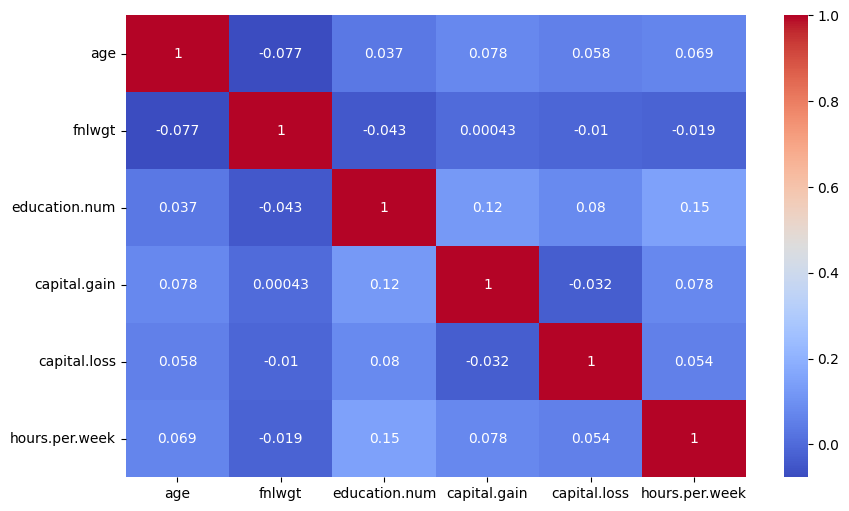

In [9]:
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

In [10]:
X = df.drop(columns = ['income'])
y = df["income"]
y = y.map({'<=50K': 0, '>50K': 1})


In [11]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.3 , random_state = 42)

In [12]:
from sklearn.impute import SimpleImputer
cols = ["workclass" , "occupation" , "native.country"]
imputer_obj = SimpleImputer(missing_values=np.nan, strategy="most_frequent")
X_train[cols] = imputer_obj.fit_transform(X_train[cols])
X_test[cols] = imputer_obj.transform(X_test[cols])

In [13]:
obj = df.select_dtypes("object").columns

In [14]:
for col in obj:
    print(f"Number of Values : {df[col].nunique()}")
    print(f"{col} :", end= " ")
    print(df[col].unique())
    print("*" * 50)

Number of Values : 8
workclass : [nan 'Private' 'State-gov' 'Federal-gov' 'Self-emp-not-inc' 'Self-emp-inc'
 'Local-gov' 'Without-pay' 'Never-worked']
**************************************************
Number of Values : 16
education : ['HS-grad' 'Some-college' '7th-8th' '10th' 'Doctorate' 'Prof-school'
 'Bachelors' 'Masters' '11th' 'Assoc-acdm' 'Assoc-voc' '1st-4th' '5th-6th'
 '12th' '9th' 'Preschool']
**************************************************
Number of Values : 7
marital.status : ['Widowed' 'Divorced' 'Separated' 'Never-married' 'Married-civ-spouse'
 'Married-spouse-absent' 'Married-AF-spouse']
**************************************************
Number of Values : 14
occupation : [nan 'Exec-managerial' 'Machine-op-inspct' 'Prof-specialty'
 'Other-service' 'Adm-clerical' 'Craft-repair' 'Transport-moving'
 'Handlers-cleaners' 'Sales' 'Farming-fishing' 'Tech-support'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']
**************************************************
Number of

In [15]:
df.select_dtypes("object").columns

Index(['workclass', 'education', 'marital.status', 'occupation',
       'relationship', 'race', 'sex', 'native.country', 'income'],
      dtype='object')

In [16]:
from sklearn.preprocessing import OneHotEncoder

In [17]:
cols = ['sex', 'workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

X_train_ohe = ohe.fit_transform(X_train[cols])
X_test_ohe = ohe.transform(X_test[cols])

X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=ohe.get_feature_names_out(cols), index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=ohe.get_feature_names_out(cols), index=X_test.index)

X_train = pd.concat([X_train.drop(columns=cols), X_train_ohe_df], axis=1)
X_test = pd.concat([X_test.drop(columns=cols), X_test_ohe_df], axis=1)

In [18]:
from sklearn.preprocessing import MinMaxScaler

In [19]:
sc = ["fnlwgt", "age" , "native.country", "hours.per.week", "capital.loss"]

In [20]:
from sklearn.preprocessing import MinMaxScaler

In [21]:
scaler = MinMaxScaler()
for col in sc :
  X_train_scaled = scaler.fit_transform(X_train)
  X_test_scaled= scaler.transform(X_test)

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

In [23]:
logistic = LogisticRegression()
logistic.fit(X_train_scaled, y_train)
y_pred_log = logistic.predict(X_test)

c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

acc = accuracy_score(y_test, y_pred_log)
prec = precision_score(y_test, y_pred_log)
rec = recall_score(y_test, y_pred_log)
f1 = f1_score(y_test, y_pred_log)
cm = confusion_matrix(y_test, y_pred_log)
cr = classification_report(y_test, y_pred_log)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print(f"Precision Score: {prec:.4f}")
print("*" * 50)
print(f"Recall Score: {rec:.4f}")
print("*" * 50)
print(f"F1 Score: {f1:.4f}")
print("*" * 50)
print("\nConfusion Matrix:")
print(cm)
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.2395
**************************************************
Precision Score: 0.2395
**************************************************
Recall Score: 1.0000
**************************************************
F1 Score: 0.3865
**************************************************

Confusion Matrix:
[[   0 7429]
 [   0 2340]]
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00      7429
           1       0.24      1.00      0.39      2340

    accuracy                           0.24      9769
   macro avg       0.12      0.50      0.19      9769
weighted avg       0.06      0.24      0.09      9769



c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\MS\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mod

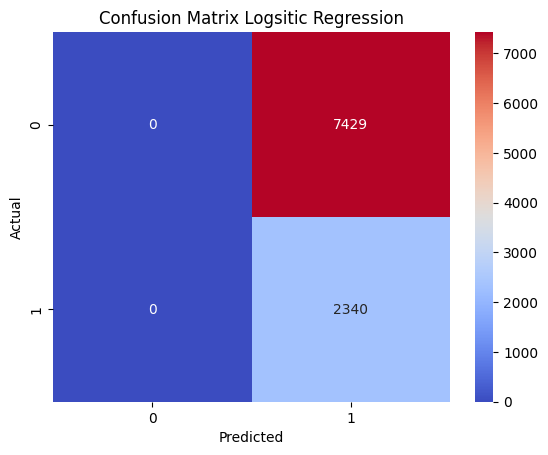

In [25]:
sns.heatmap(cm, annot=True, fmt='g',  cmap='coolwarm')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Logsitic Regression')
plt.show()

In [26]:
Naive = GaussianNB()
Naive.fit(X_train_scaled, y_train)
y_pred_naive = Naive.predict(X_test_scaled)

In [27]:
acc = accuracy_score(y_test, y_pred_naive)
prec = precision_score(y_test, y_pred_naive)
rec = recall_score(y_test, y_pred_naive)
f1 = f1_score(y_test, y_pred_naive)
cmn = confusion_matrix(y_test, y_pred_naive)
cr = classification_report(y_test, y_pred_naive)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print(f"Precision Score: {prec:.4f}")
print("*" * 50)
print(f"Recall Score: {rec:.4f}")
print("*" * 50)
print(f"F1 Score: {f1:.4f}")
print("*" * 50)
print("\nConfusion Matrix:")
print(cm)
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.4657
**************************************************
Precision Score: 0.3055
**************************************************
Recall Score: 0.9667
**************************************************
F1 Score: 0.4643
**************************************************

Confusion Matrix:
[[   0 7429]
 [   0 2340]]
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.31      0.47      7429
           1       0.31      0.97      0.46      2340

    accuracy                           0.47      9769
   macro avg       0.64      0.64      0.47      9769
weighted avg       0.81      0.47      0.47      9769



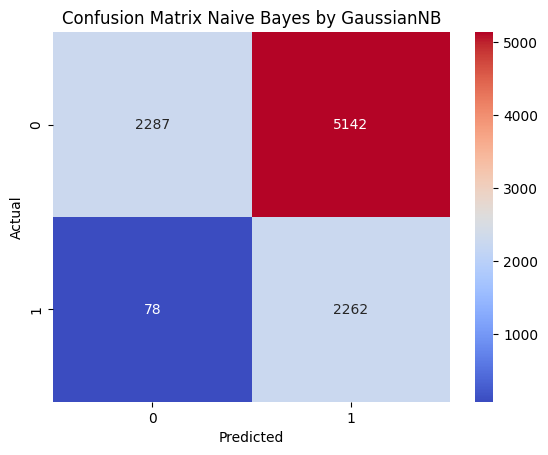

In [28]:
sns.heatmap(cmn, annot=True, fmt='g',  cmap='coolwarm')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Naive Bayes by GaussianNB')
plt.show()

In [29]:
Knn = KNeighborsClassifier()
Knn.fit(X_train_scaled, y_train)
y_pred_knn = Knn.predict(X_test_scaled)

In [30]:
acc = accuracy_score(y_test, y_pred_knn)
prec = precision_score(y_test, y_pred_knn)
rec = recall_score(y_test, y_pred_knn)
f1 = f1_score(y_test, y_pred_knn)
cmk = confusion_matrix(y_test, y_pred_knn)
cr = classification_report(y_test, y_pred_knn)

print(f"Accuracy Score: {acc:.4f}")
print("*" * 50)
print(f"Precision Score: {prec:.4f}")
print("*" * 50)
print(f"Recall Score: {rec:.4f}")
print("*" * 50)
print(f"F1 Score: {f1:.4f}")
print("*" * 50)
print("\nConfusion Matrix:")
print(cm)
print("*" * 50)
print("\nClassification Report:")
print(cr)

Accuracy Score: 0.8192
**************************************************
Precision Score: 0.6393
**************************************************
Recall Score: 0.5628
**************************************************
F1 Score: 0.5986
**************************************************

Confusion Matrix:
[[   0 7429]
 [   0 2340]]
**************************************************

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.88      7429
           1       0.64      0.56      0.60      2340

    accuracy                           0.82      9769
   macro avg       0.75      0.73      0.74      9769
weighted avg       0.81      0.82      0.82      9769



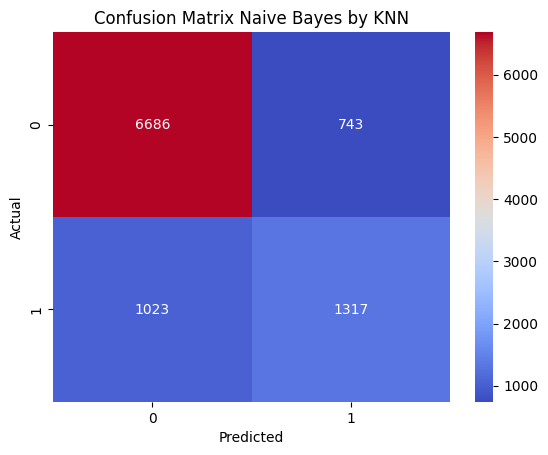

In [31]:
sns.heatmap(cmk, annot=True, fmt='g', cmap='coolwarm')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Naive Bayes by KNN')
plt.show()

In [32]:
alg = [y_pred_log , y_pred_naive , y_pred_knn]

rep_alg = pd.DataFrame(columns = ["Accuracy Score" , "Precision Score" , "Recall Score" , "F1 Score" , "Confusion Matrix"])
for pred in alg :
    {"Accuracy Score" : accuracy_score(y_test, pred),
    "Precision Score":   precision_score(y_test, pred),
    "Recall Score"  : recall_score(y_test, pred),
    "F1 Score" :  f1_score(y_test, pred),
    "Confusion Matrix" :  confusion_matrix(y_test, pred)}


In [33]:

alg = [y_pred_log, y_pred_naive, y_pred_knn]

rep_alg = pd.DataFrame(
    columns=[
        "Algorithm",
        "Accuracy Score",
        "Precision Score",
        "Recall Score",
        "F1 Score"
    ]
)

for name, pred in zip(["Logistic Regression", "Naive Bayes", "KNN"], alg):
    rep_alg.loc[len(rep_alg)] = [
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ]

rep_alg.T


,0,1,2
Algorithm,Logistic Regression,Naive Bayes,KNN
Accuracy Score,0.239533,0.465657,0.819224
Precision Score,0.239533,0.305511,0.63932
Recall Score,1.0,0.966667,0.562821
F1 Score,0.386489,0.464286,0.598636


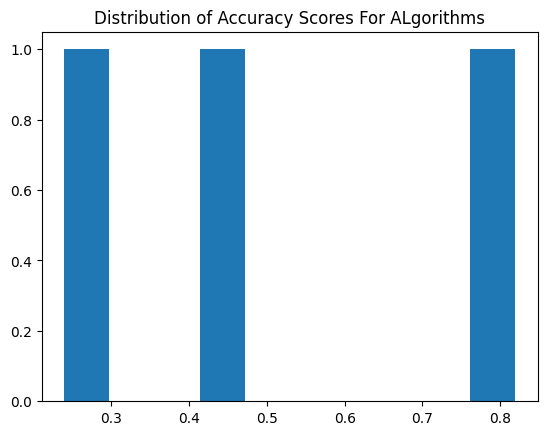

In [34]:
plt.hist(rep_alg.sort_values(by="Accuracy Score", ascending=False)["Accuracy Score"])
plt.title("Distribution of Accuracy Scores For ALgorithms")
plt.show()

## Model Comparison


In [35]:
_Xtr = globals().get("X_train_scaled", X_train)
_Xte = globals().get("X_test_scaled", X_test)

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=10, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(_Xtr, y_train)
    p = m.predict(_Xte)
    results.append({"Model": name,
                    "Train Accuracy": accuracy_score(y_train, m.predict(_Xtr)),
                    "Test Accuracy": accuracy_score(y_test, p),
                    "Precision": precision_score(y_test, p, average="weighted", zero_division=0),
                    "Recall": recall_score(y_test, p, average="weighted", zero_division=0),
                    "F1": f1_score(y_test, p, average="weighted", zero_division=0)})

results_df = pd.DataFrame(results).sort_values("F1", ascending=False).reset_index(drop=True)
results_df

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1
0,Gradient Boosting,0.869033,0.864879,0.859623,0.864879,0.857238
1,Random Forest,1.000000,0.854028,0.848147,0.854028,0.849398
2,Decision Tree,0.871490,0.853414,0.846499,0.853414,0.845736
3,Logistic Regression,0.850605,0.848500,0.841168,0.848500,0.841625
